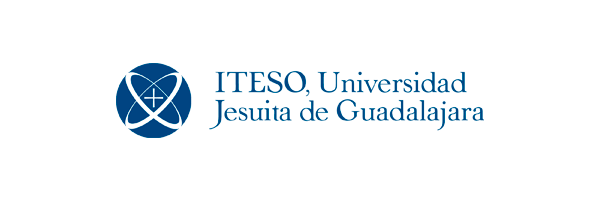

# Reporte de Prácticas de Perceptrón Multicapa (Regresión)

## Tarea 8

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 27 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 1: predicción de un paso](#practica1)
    - 2.1 [Definición del problema](#p1-definicion)
    - 2.2 [Descripción del algoritmo](#p1-algoritmo)
    - 2.3 [Implementación](#p1-implementacion)
    - 2.4 [Pruebas y resultados](#p1-pruebas)
    - 2.5 [Análisis y conclusiones de la práctica](#p1-analisis)
3. [Práctica 2: predicción multihorizonte con datos normalizados](#practica2)
    - 3.1 [Definición del problema](#p2-definicion)
    - 3.2 [Descripción del algoritmo](#p2-algoritmo)
    - 3.3 [Implementación](#p2-implementacion)
    - 3.4 [Pruebas y resultados](#p2-pruebas)
    - 3.5 [Análisis y conclusiones de la práctica](#p2-analisis)
4. [Conclusiones](#conclusiones)
    - 4.1 [Conclusiones personales](#conclusiones-personales)
    - 4.2 [Conclusiones generales](#conclusiones-generales)

<a id="introduccion"></a>

## 1. Introducción y objetivos

En la tarea anterior trabajamos con redes competitivas, que aprenden **sin supervisión**. En esta tarea regresamos al **aprendizaje supervisado**, pero con una red más completa que el perceptrón simple y ADALINE: el **perceptrón multicapa** (MLP, *Multilayer Perceptron*).

Un MLP tiene una **capa de entrada**, una o más **capas ocultas** y una **capa de salida**. Cada neurona hace una suma ponderada de sus entradas, le suma un sesgo y le aplica una **función de activación**. Las capas ocultas con activaciones no lineales permiten que la red aprenda relaciones que no son líneas rectas, algo que un perceptrón de una sola capa no puede hacer. Los pesos se ajustan con la **retropropagación del error** (*backpropagation*): la red compara su predicción con el valor real, calcula el error y lo manda hacia atrás, capa por capa, para saber cuánto debe cambiar cada peso.

En las dos prácticas el MLP se usa para **regresión**, es decir, para predecir un número y no una clase. El problema es estimar el precio de un activo de la Bolsa Mexicana de Valores a partir de sus precios anteriores. Para eso la serie de tiempo se convierte en una tabla de entradas y salidas usando **rezagos**: si conocemos los últimos $p$ precios, la red aprende a estimar el que sigue,

$$\hat{y}(t) = f\big(y(t-1),\, y(t-2),\, \dots,\, y(t-p)\big)$$

donde $f$ es la función que aprende el MLP. En la **Práctica 1** la red predice **un solo valor** (el día siguiente). En la **Práctica 2** predice **cinco valores a la vez** (varios días hacia adelante) y trabaja con **datos normalizados**.

**Objetivo general:** implementar perceptrones multicapa de regresión para predecir el precio de un activo de la BMV a partir de sus valores pasados, y evaluar qué tan buenas son sus predicciones con datos que la red no vio durante el entrenamiento.

**Objetivos específicos**
- Transformar una serie de tiempo en un problema supervisado con una matriz de rezagos.
- Entrenar un MLP con `MLPRegressor` de scikit-learn para predecir el precio del día siguiente (Práctica 1).
- Comparar arquitecturas, números de rezagos y funciones de activación, y contrastar los resultados con un modelo ingenuo de referencia.
- Extender el modelo para predecir cinco días hacia adelante con una sola red de cinco salidas (Práctica 2).
- Analizar el efecto de normalizar los datos y revisar la curva de pérdida durante el entrenamiento.
- Medir el desempeño con el 10 % final de la serie, que se reserva como conjunto de prueba.

<a id="practica1"></a>

## 2. Práctica 1: predicción de un paso

<a id="p1-definicion"></a>

### 2.1 Definición del problema

El archivo `Datos_BMV.csv` (sin encabezado) guarda los precios diarios de 35 activos de la BMV. Se toma la columna con **índice 10** en Python (columna 11 del archivo, activo BMV_11), que tiene **774 observaciones** con precios entre 16.53 y 20.02.

Se quiere predecir el **precio del día siguiente** usando los precios de los $n_{rez}$ días anteriores. Es un problema de **regresión supervisada**: cada fila de la matriz de rezagos trae sus entradas y la respuesta correcta. Se busca:

1. Construir la matriz de rezagos: las entradas son $y(t-1), \dots, y(t-n_{rez})$ y la salida es $y(t)$. Con $n_{rez}=20$ (código base) se obtienen $774-20 = 754$ muestras.
2. Entrenar el MLP con el **90 % inicial** (679 muestras con 20 rezagos) y probarlo con el **10 % final** (75 muestras). La división respeta el orden en el tiempo, para que la red no use datos del futuro al aprender.
3. Usar la red entrenada para predecir el **siguiente valor** después del último dato de la serie.
4. Revisar cómo cambian los resultados con la arquitectura, el número de rezagos y la función de activación, y compararlos con el **modelo ingenuo** $\hat{y}(t) = y(t-1)$ (mañana vale lo mismo que hoy).

<a id="p1-algoritmo"></a>

### 2.2 Descripción del algoritmo

**Esquema del MLP** (código base: 20 rezagos y capas ocultas `(10, 5, 2)`)

```
  Capa de entrada            Capas ocultas (activación f)            Capa de salida
  (20 rezagos)                                                       (identidad)

   y(t-1)  ──┐
   y(t-2)  ──┤      ┌───────────┐     ┌───────────┐     ┌───────────┐
   y(t-3)  ──┼────► │ 10 neur.  │───► │  5 neur.  │───► │  2 neur.  │───►  ŷ(t)
     ...     │      └───────────┘     └───────────┘     └───────────┘
   y(t-20) ──┘
          W1 (20x10), b1    W2 (10x5), b2     W3 (5x2), b3     W4 (2x1), b4
```

Esta red tiene **280 parámetros** (pesos + sesgos). Cada flecha representa una conexión completa: todas las neuronas de una capa se conectan con todas las de la siguiente.

1. **Matriz de rezagos:** se crea `temp` con $n_{rez}+1$ columnas, donde la columna $k$ es la serie recorrida $k$ días: `temp[:, k] = data[nrez-k : N-k]`. La columna 0 es el valor actual $y(t)$ (salida) y las columnas $1,\dots,n_{rez}$ son los rezagos (entradas).
2. **División cronológica:** las primeras $n_{dat} = \text{round}(0.9\,N)$ filas son de entrenamiento y el resto de prueba.
3. **Propagación hacia adelante:** con $a^{(0)} = x$ (vector de rezagos), cada capa oculta calcula
$$z^{(l)} = W^{(l)}\,a^{(l-1)} + b^{(l)}, \qquad a^{(l)} = f\big(z^{(l)}\big)$$
   y la capa de salida usa la identidad, $\hat{y} = W^{(L)}a^{(L-1)} + b^{(L)}$, porque en regresión la salida puede ser cualquier número real. Las activaciones disponibles en `MLPRegressor` son:

| Activación | Fórmula $f(z)$ | Rango |
|---|---|---|
| `identity` | $z$ | $(-\infty, \infty)$ |
| `logistic` | $1/(1+e^{-z})$ | $(0, 1)$ |
| `tanh` | $\tanh(z)$ | $(-1, 1)$ |
| `relu` | $\max(0, z)$ | $[0, \infty)$ |

   Con `identity` (código base) toda la red es **lineal**: una composición de funciones lineales sigue siendo lineal, así que la red equivale a una regresión lineal sobre los rezagos (un modelo autorregresivo), sin importar cuántas capas tenga.
4. **Función de pérdida:** `MLPRegressor` minimiza el error cuadrático medio más una penalización L2 sobre los pesos ($\alpha = 0.0001$ por defecto):
$$L = \frac{1}{2n}\sum_{i=1}^{n}\big(y_i - \hat{y}_i\big)^2 + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
5. **Retropropagación:** el error de la salida, $\delta^{(L)} = \hat{y} - y$, se manda hacia atrás con
$$\delta^{(l)} = \big(W^{(l+1)}\big)^{\top}\delta^{(l+1)} \odot f'\big(z^{(l)}\big), \qquad \frac{\partial L}{\partial W^{(l)}} \propto \delta^{(l)}\,\big(a^{(l-1)}\big)^{\top}$$
   Con estos gradientes, el optimizador **L-BFGS** (`solver='lbfgs'`) actualiza todos los pesos. L-BFGS es un método cuasi-Newton que usa una aproximación de la curvatura de la pérdida; funciona bien con pocos datos como los de esta práctica. Se detiene al converger o al llegar a `max_iter = 1000`.
6. **Simulación y evaluación:** se predice toda la serie (`red.predict(X)`) y se calculan, en entrenamiento y en prueba, con $e_i = y_i - \hat{y}_i$:
$$\text{RMSE} = \sqrt{\tfrac{1}{n}\textstyle\sum e_i^2}, \quad \text{MAE} = \tfrac{1}{n}\textstyle\sum |e_i|, \quad \text{MAPE} = \tfrac{100}{n}\textstyle\sum \left|\tfrac{e_i}{y_i}\right|, \quad R^2 = 1 - \dfrac{\sum e_i^2}{\sum (y_i - \bar{y})^2}$$
7. **Predicción del siguiente valor:** la entrada debe ser el vector de los **últimos $n_{rez}$ datos reales**, $[\,y(T), y(T-1), \dots, y(T-n_{rez}+1)\,]$, para obtener $\hat{y}(T+1)$. En el código base se usa `A = X[:, -1:]`, que es la última fila de la matriz de rezagos, $[\,y(T-1), \dots, y(T-n_{rez})\,]$; con esa entrada la red estima $y(T)$, un dato que ya se conoce, por eso se corrige en la implementación.

**Pseudocódigo**
```
INICIO
    data <- columna con índice 10 de Datos_BMV.csv      // 774 precios
    nrez <- 20
    PARA k = 0 HASTA nrez HACER
        temp[:, k] <- data[nrez-k : N-k]                 // col 0 = y(t), col k = y(t-k)
    FIN PARA
    Y <- temp[:, 0]                X <- temp[:, 1..nrez]
    ndat <- round(0.9 * número de filas)
    (Xtrain, Ytrain) <- primeras ndat filas    (Xprueba, Yprueba) <- filas restantes
    red <- MLPRegressor(capas ocultas, activación, solver = 'lbfgs', max_iter = 1000)
    REPETIR hasta converger o llegar a max_iter          // red.fit(Xtrain, Ytrain)
        ŷ <- propagación hacia adelante de Xtrain
        L <- error cuadrático medio / 2 + penalización L2
        gradientes <- retropropagación de (ŷ - Ytrain)
        actualizar W y b con L-BFGS
    FIN REPETIR
    Yg <- red.predict(X)                                 // simulación de toda la serie
    Calcular RMSE, MAE, MAPE y R² en entrenamiento y prueba
    x_sig <- [y(T), y(T-1), ..., y(T-nrez+1)]            // últimos nrez datos reales
    ŷ(T+1) <- red.predict(x_sig)
    Graficar datos reales, simulación y predicción del siguiente valor
FIN
```

<a id="p1-implementacion"></a>

### 2.3 Implementación

#### Carga de datos

Observaciones: 774
Mínimo: 16.53 | Máximo: 20.02 | Último valor: 17.36


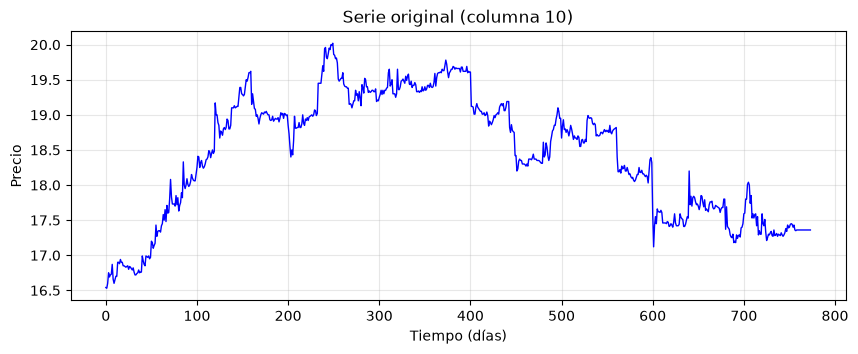

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

# Cargar el CSV (sin encabezado) y extraer la columna del activo
df = pd.read_csv('Datos_BMV.csv', header=None)
data = df.iloc[:, 10].values

print('Observaciones:', len(data))
print('Mínimo: %.2f | Máximo: %.2f | Último valor: %.2f' % (data.min(), data.max(), data[-1]))

plt.figure(figsize=(10, 3.5))
plt.plot(data, 'b-', lw=1)
plt.title('Serie original (columna 10)'); plt.xlabel('Tiempo (días)'); plt.ylabel('Precio'); plt.grid(alpha=.3)
plt.show()

#### Metodología

**Matriz de rezagos.** Igual que en `MLP_1.py`: la entrada son los `nrez` valores anteriores y la salida es el valor actual. Se usa el **90 % inicial** para entrenar y el **10 % final** como conjunto de prueba.

**Dos bloques de pruebas**
- **Bloque A (código base):** `activation='identity'`, datos sin escalar.
- **Bloque B (variante no lineal):** `activation='tanh'` con estandarización de entradas y salida (el escalador se ajusta solo con entrenamiento).

**Rejilla:** 6 números de rezagos (1, 3, 5, 10, 20, 30) × 8 arquitecturas × 2 bloques = **96 combinaciones**. Cada una se entrena con **5 semillas** y se promedia, porque los pesos iniciales son aleatorios.

**Métricas:** RMSE, MAE, MAPE (%) y R², en entrenamiento y prueba. Referencia: modelo ingenuo *y(t) = y(t−1)*.

**Corrección importante al código base.** En `MLP_1.py`, `A = X[:, -1:]` es el vector de entrada de la última fila de X, que predice el último dato *ya conocido*, no el siguiente. Para predecir el día futuro la entrada debe ser `[y(t), y(t−1), …, y(t−nrez+1)]`, es decir, los últimos `nrez` datos reales (`data[::-1][:nrez]`), que es lo que se usa abajo. Además, `identity` es lineal, por lo que apilar capas equivale a una sola capa lineal; por eso se añade el Bloque B.

#### Funciones auxiliares y modelo de referencia (ingenuo)

In [2]:
def build(nrez):
    """Matriz de rezagos como en MLP_1.py. Devuelve X:(N, nrez) y Y:(N,)."""
    temp = np.zeros((len(data) - nrez, nrez + 1))
    for k in range(nrez + 1):
        temp[:, k] = data[nrez - k: len(data) - k]   # col 0 = tiempo actual, demás = rezagos
    return temp[:, 1:], temp[:, 0]

def metricas(y, p):
    e = y - p
    return dict(RMSE=np.sqrt(np.mean(e**2)),
                MAE=np.mean(np.abs(e)),
                MAPE=100 * np.mean(np.abs(e / y)),
                R2=1 - np.sum(e**2) / np.sum((y - y.mean())**2))

def run(nrez, arch, act, scale, seed):
    """Entrena un MLP y devuelve predicciones y el siguiente valor."""
    X, Y = build(nrez)
    nd = int(round(0.9 * len(Y)))                      # 90 % entrenamiento
    Xtr, Ytr, Xte, Yte = X[:nd], Y[:nd], X[nd:], Y[nd:]
    xnext = data[::-1][:nrez].reshape(1, -1)           # entrada correcta para el SIGUIENTE valor
    if scale:
        sx = StandardScaler().fit(Xtr); sy = StandardScaler().fit(Ytr.reshape(-1, 1))
        f = sx.transform
        g = lambda p: sy.inverse_transform(p.reshape(-1, 1)).ravel()
        ytr_fit = sy.transform(Ytr.reshape(-1, 1)).ravel()
    else:
        f = lambda A: A; g = lambda p: p; ytr_fit = Ytr
    m = MLPRegressor(hidden_layer_sizes=arch, activation=act, solver='lbfgs',
                     max_iter=1000, random_state=seed)
    m.fit(f(Xtr), ytr_fit)
    return dict(model=m, ptr=g(m.predict(f(Xtr))), pte=g(m.predict(f(Xte))),
                pall=g(m.predict(f(X))), nxt=g(m.predict(f(xnext)))[0],
                Ytr=Ytr, Yte=Yte, Y=Y, nd=nd)

In [3]:
X1, Y1 = build(1)
nd1 = int(round(0.9 * len(Y1)))
ing_tr = metricas(Y1[:nd1], X1[:nd1, 0])
ing_te = metricas(Y1[nd1:], X1[nd1:, 0])
pd.DataFrame([ing_tr, ing_te], index=['entrenamiento', 'prueba']).round(4)

,RMSE,MAE,MAPE,R2
entrenamiento,0.1089,0.0643,0.3484,0.9833
prueba,0.0920,0.0561,0.3206,0.7248


<a id="p1-pruebas"></a>

### 2.4 Pruebas y resultados

#### Experimentos: variación de arquitectura y rezagos

In [4]:
lags  = [1, 3, 5, 10, 20, 30]
archs = [(5,), (10,), (20,), (10, 5), (20, 10), (10, 5, 2), (20, 10, 5), (50, 25, 10)]
bloques = {'A': ('identity', False), 'B': ('tanh', True)}
SEEDS = range(5)

rows = []
for b, (act, sc) in bloques.items():
    for nz in lags:
        for a in archs:
            R = []
            for s in SEEDS:
                o = run(nz, a, act, sc, s)
                r = {f'{k}_ent': v for k, v in metricas(o['Ytr'], o['ptr']).items()}
                r.update({f'{k}_prueba': v for k, v in metricas(o['Yte'], o['pte']).items()})
                r['siguiente'] = o['nxt']
                R.append(r)
            R = pd.DataFrame(R)
            nparam = sum(c.size for c in o['model'].coefs_) + sum(c.size for c in o['model'].intercepts_)
            row = dict(bloque=b, activacion=act, rezagos=nz, arquitectura=str(a),
                       capas=len(a), parametros=nparam)
            for c in R.columns:
                row[c] = R[c].mean()
            row['RMSE_prueba_desv'] = R['RMSE_prueba'].std()
            rows.append(row)
    print('Bloque', b, 'terminado')

res = pd.DataFrame(rows)
print('Combinaciones probadas:', len(res))

Bloque A terminado


Bloque B terminado
Combinaciones probadas: 96


#### Tabla comparativa (todas las combinaciones)
Promedio de 5 semillas. `siguiente` = predicción del siguiente valor.

In [5]:
cols = ['bloque', 'activacion', 'rezagos', 'arquitectura', 'parametros',
        'RMSE_ent', 'MAE_ent', 'MAPE_ent', 'R2_ent',
        'RMSE_prueba', 'MAE_prueba', 'MAPE_prueba', 'R2_prueba',
        'RMSE_prueba_desv', 'siguiente']
tabla = res[cols].round(4)
pd.set_option('display.max_rows', 200, 'display.width', 250, 'display.max_columns', 30)
tabla

,bloque,activacion,rezagos,arquitectura,parametros,RMSE_ent,MAE_ent,MAPE_ent,R2_ent,RMSE_prueba,MAE_prueba,MAPE_prueba,R2_prueba,RMSE_prueba_desv,siguiente
0,A,identity,1,"(5,)",16,0.1085,0.0654,0.3542,0.9834,0.0923,0.0579,0.3313,0.7235,0.0001,17.3733
1,A,identity,1,"(10,)",31,0.1085,0.0653,0.3539,0.9834,0.0922,0.0579,0.3308,0.7237,0.0001,17.3729
2,A,identity,1,"(20,)",61,0.1085,0.0656,0.3552,0.9834,0.0924,0.0583,0.3334,0.7227,0.0002,17.3747
3,A,identity,1,"(10, 5)",81,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3320,0.7233,0.0000,17.3738
4,A,identity,1,"(20, 10)",261,0.1085,0.0654,0.3542,0.9834,0.0923,0.0579,0.3313,0.7235,0.0001,17.3733
5,A,identity,1,"(10, 5, 2)",90,0.1085,0.0654,0.3546,0.9834,0.0923,0.0581,0.3322,0.7232,0.0000,17.3739
6,A,identity,1,"(20, 10, 5)",311,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3321,0.7233,0.0000,17.3739
7,A,identity,1,"(50, 25, 10)",1646,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3320,0.7233,0.0000,17.3738
8,A,identity,3,"(5,)",26,0.1072,0.0646,0.3496,0.9835,0.0904,0.0558,0.3188,0.7343,0.0001,17.3727
9,A,identity,3,"(10,)",51,0.1073,0.0649,0.3514,0.9835,0.0906,0.0564,0.3224,0.7330,0.0010,17.3752


#### Resumen: RMSE de prueba por rezagos y arquitectura

In [6]:
orden = [str(a) for a in archs]
for b in ['A', 'B']:
    print(f'--- Bloque {b} ({bloques[b][0]}) ---')
    pv = res[res.bloque == b].pivot(index='arquitectura', columns='rezagos', values='RMSE_prueba').loc[orden]
    display(pv.round(4))
print('Referencia modelo ingenuo (prueba): %.4f' % ing_te['RMSE'])

--- Bloque A (identity) ---


rezagos,1,3,5,10,20,30
arquitectura,,,,,,
"(5,)",0.0923,0.0904,0.0907,0.0911,0.0913,0.0935
"(10,)",0.0922,0.0906,0.0911,0.0906,0.0917,0.0923
"(20,)",0.0924,0.0905,0.0905,0.0916,0.0902,0.0937
"(10, 5)",0.0923,0.0902,0.0906,0.0905,0.0910,0.0925
"(20, 10)",0.0923,0.0907,0.0911,0.0913,0.0923,0.0959
"(10, 5, 2)",0.0923,0.0906,0.0902,0.0911,0.0904,0.0917
"(20, 10, 5)",0.0923,0.0900,0.0903,0.0912,0.0923,0.0947
"(50, 25, 10)",0.0923,0.0916,0.0912,0.0917,0.0917,0.0958


--- Bloque B (tanh) ---


rezagos,1,3,5,10,20,30
arquitectura,,,,,,
"(5,)",0.0919,0.0912,0.0944,0.0954,0.1064,0.1141
"(10,)",0.0919,0.0907,0.0933,0.1028,0.1173,0.1389
"(20,)",0.0916,0.0895,0.0928,0.1106,0.1201,0.1839
"(10, 5)",0.0920,0.0904,0.0933,0.1109,0.1412,0.1738
"(20, 10)",0.0920,0.0902,0.1039,0.1191,0.1373,0.2191
"(10, 5, 2)",0.0919,0.0900,0.0900,0.1056,0.1327,0.2356
"(20, 10, 5)",0.0920,0.0897,0.1000,0.1508,0.1942,0.3241
"(50, 25, 10)",0.0920,0.0889,0.0960,0.1474,0.1808,0.3216


Referencia modelo ingenuo (prueba): 0.0920


#### Selección de la mejor configuración y predicción del siguiente valor

In [7]:
top = res.sort_values('RMSE_prueba').head(6)[['bloque', 'rezagos', 'arquitectura', 'parametros',
                                              'RMSE_ent', 'RMSE_prueba', 'R2_prueba', 'RMSE_prueba_desv', 'siguiente']]
display(top.round(4))

mejor = res.sort_values('RMSE_prueba').iloc[0]
print('\nConfiguración seleccionada: bloque %s | %d rezagos | capas %s' % (mejor.bloque, mejor.rezagos, mejor.arquitectura))
print('RMSE prueba = %.4f | R2 prueba = %.3f | MAPE prueba = %.3f %%' % (mejor.RMSE_prueba, mejor.R2_prueba, mejor.MAPE_prueba))
print('PREDICCIÓN DEL SIGUIENTE VALOR (promedio de 5 semillas): %.3f' % mejor.siguiente)
print('Último dato real: %.2f' % data[-1])

,bloque,rezagos,arquitectura,parametros,RMSE_ent,RMSE_prueba,R2_prueba,RMSE_prueba_desv,siguiente
63,B,3,"(50, 25, 10)",1746,0.0998,0.0889,0.7430,0.0008,17.3843
58,B,3,"(20,)",101,0.1012,0.0895,0.7397,0.0007,17.3831
62,B,3,"(20, 10, 5)",351,0.1011,0.0897,0.7387,0.0009,17.3838
69,B,5,"(10, 5, 2)",130,0.0966,0.0900,0.7369,0.0030,17.3848
61,B,3,"(10, 5, 2)",110,0.1011,0.0900,0.7369,0.0021,17.3822
14,A,3,"(20, 10, 5)",351,0.1074,0.0900,0.7367,0.0010,17.3710



Configuración seleccionada: bloque B | 3 rezagos | capas (50, 25, 10)
RMSE prueba = 0.0889 | R2 prueba = 0.743 | MAPE prueba = 0.343 %
PREDICCIÓN DEL SIGUIENTE VALOR (promedio de 5 semillas): 17.384
Último dato real: 17.36


#### Gráficas de los casos representativos
Solo se grafican tres casos: la **mejor configuración**, un caso de **subajuste** y el de **mayor complejidad/rezagos** (sobreajuste). Se muestra la corrida cuya semilla queda más cerca del promedio de las 5 semillas. A la derecha, un zoom del conjunto de prueba.

In [8]:
def graficar(nombre, nrez, arch, act, sc):
    runs = [run(nrez, arch, act, sc, s) for s in SEEDS]
    rm = np.array([metricas(r['Yte'], r['pte'])['RMSE'] for r in runs])
    o = runs[int(np.argmin(np.abs(rm - rm.mean())))]          # semilla representativa
    n, nd = len(o['Y']), o['nd']; t = np.arange(1, n + 1)
    mt, me = metricas(o['Yte'], o['pte']), metricas(o['Ytr'], o['ptr'])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
    ax[0].plot(t, o['Y'], 'b-', lw=1, label='Datos reales')
    ax[0].plot(t, o['pall'], 'r-', lw=.8, label='Simulación MLP')
    ax[0].axvline(nd + .5, color='gray', ls='--', label='Inicio de prueba (10 %)')
    ax[0].plot(n + 1, o['nxt'], 'g*', ms=13, label='Predicción siguiente: %.3f' % o['nxt'])
    ax[0].set(title='Serie completa', xlabel='Tiempo (días)', ylabel='Precio'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
    ax[1].plot(t[nd:], o['Yte'], 'b.-', lw=1, label='Datos reales (prueba)')
    ax[1].plot(t[nd:], o['pte'], 'r.-', lw=1, label='Predicción MLP (prueba)')
    ax[1].plot(n + 1, o['nxt'], 'g*', ms=13)
    ax[1].set(title='Zoom prueba — RMSE=%.4f, R²=%.3f' % (mt['RMSE'], mt['R2']), xlabel='Tiempo (días)')
    ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
    fig.suptitle(nombre, fontweight='bold'); fig.tight_layout(); plt.show()
    return dict(caso=nombre, RMSE_ent=me['RMSE'], RMSE_prueba=mt['RMSE'], R2_prueba=mt['R2'], siguiente=o['nxt'])

casos = []

##### Caso 1: mejor configuración

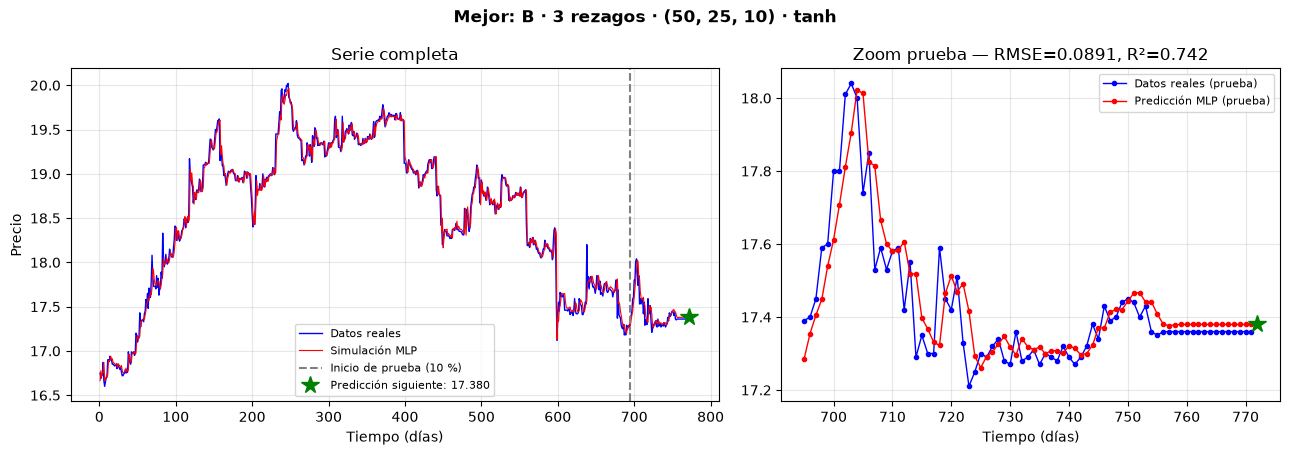

In [9]:
# Se grafica la configuración seleccionada en la tabla (menor RMSE de prueba)
act_m, sc_m = bloques[mejor.bloque]
arch_m = ast.literal_eval(mejor.arquitectura)
casos.append(graficar('Mejor: %s · %d rezagos · %s · %s' % (mejor.bloque, mejor.rezagos, mejor.arquitectura, act_m),
                      int(mejor.rezagos), arch_m, act_m, sc_m))

##### Caso 2: desempeño deficiente / subajuste

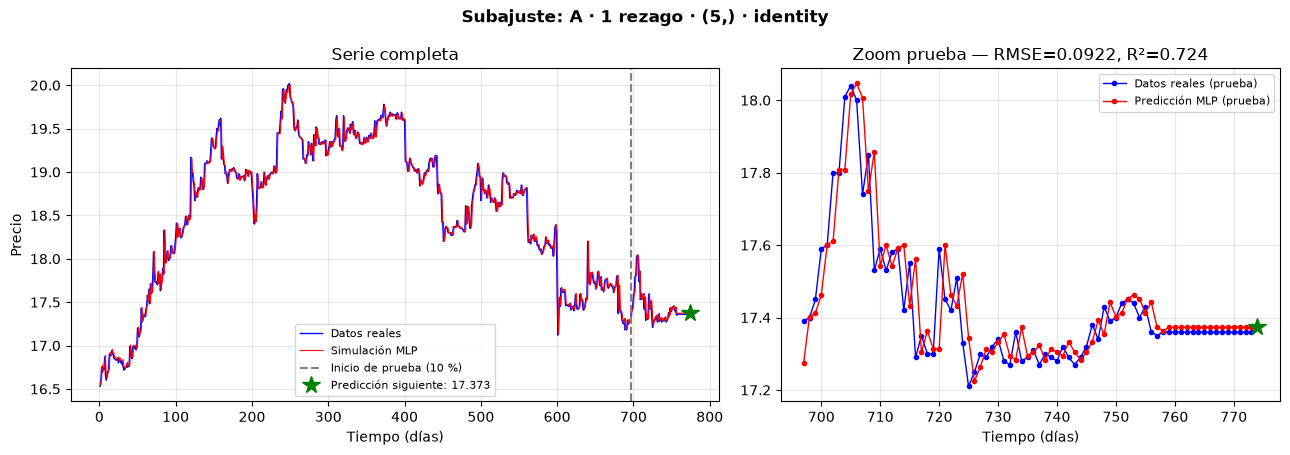

In [10]:
casos.append(graficar('Subajuste: A · 1 rezago · (5,) · identity', 1, (5,), 'identity', False))

##### Caso 3: mayor complejidad y rezagos (sobreajuste)

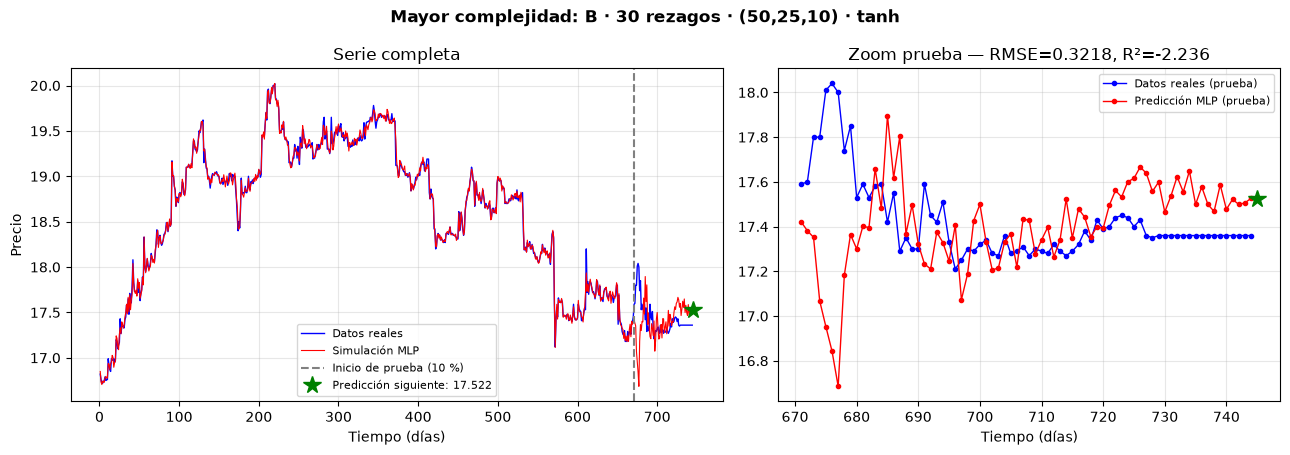

,RMSE_ent,RMSE_prueba,R2_prueba,siguiente
caso,,,,
"Mejor: B · 3 rezagos · (50, 25, 10) · tanh",0.1013,0.0891,0.7423,17.3797
"Subajuste: A · 1 rezago · (5,) · identity",0.1085,0.0922,0.7237,17.3731
"Mayor complejidad: B · 30 rezagos · (50,25,10) · tanh",0.0386,0.3218,-2.2364,17.5220


In [11]:
casos.append(graficar('Mayor complejidad: B · 30 rezagos · (50,25,10) · tanh', 30, (50, 25, 10), 'tanh', True))
pd.DataFrame(casos).set_index('caso').round(4)

#### Datos de apoyo para el análisis

In [12]:
print('RMSE de prueba promedio por número de rezagos')
display(res.groupby(['bloque', 'rezagos'])[['RMSE_ent', 'RMSE_prueba']].mean().round(4).unstack(0))
print('RMSE de prueba promedio por número de capas ocultas')
display(res.groupby(['bloque', 'capas'])[['RMSE_prueba']].mean().round(4).unstack(0))
print('Rango RMSE prueba  A: %.4f – %.4f | B: %.4f – %.4f' % (
      res[res.bloque=='A'].RMSE_prueba.min(), res[res.bloque=='A'].RMSE_prueba.max(),
      res[res.bloque=='B'].RMSE_prueba.min(), res[res.bloque=='B'].RMSE_prueba.max()))
k = 0
while data[-1 - k] == data[-1]:
    k += 1
print('Días finales con el mismo valor (%.2f): %d' % (data[-1], k))

RMSE de prueba promedio por número de rezagos


RMSE_ent         RMSE_prueba        
bloque         A       B           A       B
rezagos                                     
1         0.1085  0.1084      0.0923  0.0919
3         0.1074  0.1013      0.0906  0.0901
5         0.1074  0.0956      0.0907  0.0955
10        0.1070  0.0876      0.0911  0.1178
20        0.1073  0.0758      0.0914  0.1413
30        0.1083  0.0622      0.0938  0.2139

RMSE de prueba promedio por número de capas ocultas


RMSE_prueba        
bloque           A       B
capas                     
1           0.0915  0.1065
2           0.0917  0.1219
3           0.0918  0.1457

Rango RMSE prueba  A: 0.0900 – 0.0959 | B: 0.0889 – 0.3241
Días finales con el mismo valor (17.36): 16


<a id="p1-analisis"></a>

### 2.5 Análisis y conclusiones de la práctica

**El precio se comporta casi como un paseo aleatorio.** En el Bloque A todos los RMSE de prueba están entre 0.0900 y 0.0959, y el modelo ingenuo obtiene 0.0920. La mejor red (Bloque B, 3 rezagos, `(50,25,10)`, RMSE = 0.0889) mejora al ingenuo apenas un 3.4 %. Esa diferencia es del mismo orden que la variación entre semillas (desviaciones de 0.0005 a 0.003). Del pasado reciente, prácticamente solo aporta el último valor, y el MLP no encuentra más estructura que pueda aprovechar.

**Efecto de la arquitectura.** En el Bloque A es prácticamente nulo: el RMSE promedio es 0.0915, 0.0917 y 0.0918 con 1, 2 y 3 capas, lo esperable en una red lineal. En el Bloque B, más capas empeoran la prueba en promedio (0.107, 0.122 y 0.146) porque aumentan los parámetros sin que haya más señal que aprender. La excepción son las redes con 3 rezagos: con tan pocas entradas, incluso `(50,25,10)` se mantiene alrededor de 0.089-0.090. La diferencia entre las mejores arquitecturas de esa columna (0.0889 a 0.0900) es menor que la variación entre semillas, así que en la práctica son equivalentes.

**Efecto del número de rezagos.** Pasar de 1 a 3 rezagos mejora ligeramente (A: 0.0923 → 0.0906; B: 0.0919 → 0.0901). A partir de ahí, en el Bloque A el error casi no cambia y sube un poco con 30 rezagos (0.0938). En el Bloque B el error de entrenamiento baja de 0.108 a 0.062 mientras el de prueba sube de 0.092 a 0.214. Es un sobreajuste clásico: cada rezago extra agrega entradas y pesos que la red usa para memorizar ruido.

**Subajuste vs. sobreajuste.** El caso de subajuste (1 rezago, red lineal) falla por falta de capacidad: su error de entrenamiento (0.1085) es el más alto y coincide con el del modelo ingenuo (0.1089), y en el zoom de prueba se ve que la predicción es la serie real recorrida un día. El caso complejo (30 rezagos, `(50,25,10)`, `tanh`) falla por exceso de capacidad: tiene el error de entrenamiento más bajo (0.039) y el de prueba más alto (0.322, R² = −2.24). La mejor configuración queda en un punto intermedio: pocos rezagos y una no linealidad que mejora ligeramente al modelo lineal.

**Sobre las métricas.** El R² de prueba (~0.72-0.74) es menor que el de entrenamiento (>0.98). No es porque los modelos predigan peor, sino porque el periodo de prueba es más estable y su varianza es pequeña. El error relativo es bajo (MAPE ≈ 0.32-0.34 %). Además, los últimos 16 datos están congelados en 17.36, lo que favorece a cualquier modelo que repita el último valor.

**Predicción del siguiente valor.** La configuración seleccionada predice **17.384** (promedio de 5 semillas), y todos los modelos razonables predicen entre 17.37 y 17.39, prácticamente igual al último dato (17.36). El modelo sobreajustado se aleja (≈ 17.52) sin justificación en los datos.

<a id="practica2"></a>

## 3. Práctica 2: predicción multihorizonte con datos normalizados

<a id="p2-definicion"></a>

### 3.1 Definición del problema

Se usa el mismo activo de la Práctica 1 (columna con índice 10 de `Datos_BMV.csv`, 774 observaciones). La diferencia es que ahora la red no predice un solo día: con los **20 precios más recientes** predice los **5 días siguientes a la vez**. Es una regresión con **salida múltiple**: una sola red con **5 neuronas de salida**, una por cada horizonte.

Cambios respecto a la Práctica 1:
- **Matriz de rezagos más ancha:** se usan $n_{rez} = 20 + 5 - 1 = 24$ rezagos, es decir, 25 columnas. Las primeras 5 son las salidas y las otras 20 son las entradas. Quedan $774 - 24 = 750$ muestras: **675 de entrenamiento** (90 %) y **75 de prueba** (10 %).
- **Datos normalizados** con z-score, para que entradas y salidas queden en la misma escala, alrededor de 0.
- **Optimizador Adam** en lugar de L-BFGS, lo que permite guardar y graficar la **curva de pérdida** (`loss_curve_`).

Se busca:

1. Construir la matriz con 20 entradas y 5 salidas, y normalizarla.
2. Entrenar un MLP con capas ocultas `(10, 10, 10)`, activación `identity`, `solver='adam'` y `max_iter = 1000` (código base) con el 90 % inicial.
3. Simular toda la serie y comparar, para cada horizonte $t+1, \dots, t+5$, los valores reales contra los predichos.
4. Revisar la curva de pérdida para ver cómo y cuándo converge el entrenamiento.
5. Analizar cómo cambia el error conforme el horizonte se aleja y qué efecto tienen la normalización, la arquitectura y la activación.

<a id="p2-algoritmo"></a>

### 3.2 Descripción del algoritmo

**Orden de las columnas.** Igual que antes, la columna $k$ de `data` es la serie recorrida $k$ días. Si $\tau = t-5$ es el último día que la red conoce, las entradas son $y(\tau), \dots, y(\tau-19)$ y las salidas son $y(\tau+1), \dots, y(\tau+5)$. La **primera fila de `Y` es el horizonte más lejano** ($\tau+5$) y la quinta es el más cercano ($\tau+1$); por eso las gráficas del código base se titulan `Precio(t+{salidas - k})`.

| Columna de `data` | Contenido | Papel | Horizonte |
|---|---|---|---|
| 0 | $y(t)$ | Salida `Y[0]` | $\tau+5$ |
| 1 | $y(t-1)$ | Salida `Y[1]` | $\tau+4$ |
| 2 | $y(t-2)$ | Salida `Y[2]` | $\tau+3$ |
| 3 | $y(t-3)$ | Salida `Y[3]` | $\tau+2$ |
| 4 | $y(t-4)$ | Salida `Y[4]` | $\tau+1$ |
| 5 … 24 | $y(t-5) \dots y(t-24)$ | 20 entradas | — |

**Esquema del MLP** (capas ocultas `(10, 10, 10)`, 20 entradas y 5 salidas)

```
  Capa de entrada            Capas ocultas (identity)                  Capa de salida (5)
  (20 rezagos, z-score)

   ỹ(τ)     ──┐                                                    ┌──►  ỹ(τ+5)   Y[0]
   ỹ(τ-1)   ──┤     ┌───────────┐    ┌───────────┐    ┌───────────┐ ├──►  ỹ(τ+4)   Y[1]
   ỹ(τ-2)   ──┼───► │ 10 neur.  │──► │ 10 neur.  │──► │ 10 neur.  │─┼──►  ỹ(τ+3)   Y[2]
     ...      │     └───────────┘    └───────────┘    └───────────┘ ├──►  ỹ(τ+2)   Y[3]
   ỹ(τ-19)  ──┘                                                    └──►  ỹ(τ+1)   Y[4]
            W1 (20x10), b1     W2 (10x10), b2    W3 (10x10), b3    W4 (10x5), b4
```

Esta red tiene **485 parámetros**. Las 5 salidas comparten las mismas capas ocultas, así que la red aprende una sola representación del pasado y la usa para los 5 horizontes.

1. **Matriz de rezagos:** `data[:, k] = temp[nrez-k : N-k]` para $k = 0, \dots, 24$.
2. **Normalización z-score** de cada columna $j$:
$$\tilde{y}_j = \frac{y_j - \mu_j}{\sigma_j} \qquad\Longrightarrow\qquad y_j = \tilde{y}_j\,\sigma_j + \mu_j$$
   La segunda expresión sirve para **desnormalizar** las predicciones y medir el error en unidades de precio. Normalizar ayuda por dos razones: Adam avanza con pasos pequeños (tasa de aprendizaje de 0.001), pensados para valores de tamaño cercano a 1, y con precios cercanos a 17 la pérdida inicial es enorme y el entrenamiento tarda más; además, activaciones como `tanh` o `logistic` se **saturan** con entradas grandes (por ejemplo, $\tanh(17) \approx 1$) y dejan de aprender. En el código base $\mu$ y $\sigma$ se calculan con todas las filas; para que el 10 % de prueba no influya en el entrenamiento, conviene calcularlas solo con el 90 % de entrenamiento, como se hizo en la Práctica 1 con `StandardScaler`.
3. **Separación:** `Y` = columnas 0 a 4 (5 salidas) y `X` = columnas 5 a 24 (20 entradas); las primeras 675 filas son de entrenamiento.
4. **Propagación hacia adelante:** igual que en la Práctica 1, pero la capa de salida produce un vector de 5 valores, $\hat{\mathbf{y}} = W^{(4)}a^{(3)} + b^{(4)}$. Con `identity` la red completa sigue siendo **lineal**: cada salida es una combinación lineal de los 20 rezagos.
5. **Función de pérdida:** se promedia el error cuadrático sobre las $n$ muestras y las $m = 5$ salidas:
$$L = \frac{1}{2nm}\sum_{i=1}^{n}\sum_{j=1}^{m}\big(\tilde{y}_{ij} - \hat{\tilde{y}}_{ij}\big)^2 + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
6. **Entrenamiento con Adam:** en cada época se revuelven las filas de entrenamiento y se dividen en lotes de hasta 200 muestras. Para cada lote se calculan los gradientes $g$ con retropropagación y cada peso se actualiza con promedios móviles del gradiente y de su cuadrado:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2$$
$$w \leftarrow w - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \varepsilon}, \qquad \hat{m}_t = \frac{m_t}{1-\beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1-\beta_2^t}$$
   con $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\varepsilon = 10^{-8}$ (valores por defecto). Así cada peso tiene su propio tamaño de paso. La pérdida de cada época se guarda en `loss_curve_`, y el entrenamiento se detiene si la pérdida no mejora más de $10^{-4}$ durante 10 épocas seguidas o al llegar a 1000 épocas.

   **Nota de implementación (revisión técnica).** En las pruebas de la sección 3.4 se comprobó que, con estos datos, el criterio por defecto (`tol = 1e-4`) detiene a Adam alrededor de la época 100-250, cuando la pérdida todavía está bajando lentamente, y la red queda en subajuste. Por eso, en la rejilla de pruebas se usa `tol = 1e-6`, manteniendo `max_iter = 1000` y los demás valores por defecto.
7. **Simulación y evaluación:** se predicen las 5 salidas para toda la serie, se desnormalizan y, para cada horizonte, se grafican los valores reales contra los simulados y se calculan las métricas de error en entrenamiento y prueba (RMSE, MAE, MAPE y $R^2$, como en la Práctica 1).
8. **Predicción futura:** con los últimos 20 datos reales normalizados, $[\,\tilde{y}(T), \dots, \tilde{y}(T-19)\,]$, la red entrega $\hat{y}(T+1), \dots, \hat{y}(T+5)$, que se desnormalizan para obtener precios.

**Pseudocódigo**
```
INICIO
    temp <- columna con índice 10 de Datos_BMV.csv      // 774 precios
    salidas <- 5
    nrez <- 20 + salidas - 1                             // 24
    PARA k = 0 HASTA nrez HACER
        data[:, k] <- temp[nrez-k : N-k]                 // col 0 = y(t), col k = y(t-k)
    FIN PARA
    μ, σ <- media y desviación estándar de cada columna (de preferencia, solo con entrenamiento)
    data <- (data - μ) / σ                               // normalización z-score
    Y <- columnas 0..4  (5 salidas)         X <- columnas 5..24  (20 entradas)
    ndat <- round(0.9 * 750)                             // 675
    (Xtrain, Ytrain) <- primeras ndat filas
    red <- MLPRegressor((10, 10, 10), activation = 'identity', solver = 'adam', max_iter = 1000)
    PARA época = 1 HASTA max_iter HACER                  // red.fit(Xtrain, Ytrain)
        Revolver las filas de entrenamiento y dividirlas en lotes de 200
        PARA cada lote HACER
            Ŷ <- propagación hacia adelante del lote     // 5 salidas por fila
            L <- promedio de (Y - Ŷ)² / 2 + penalización L2
            gradientes <- retropropagación
            actualizar W y b con Adam
        FIN PARA
        Guardar L en loss_curve_
        SI L no mejora más de 1e-4 en 10 épocas seguidas ENTONCES terminar
    FIN PARA
    Yg <- red.predict(X)                                 // 5 predicciones por fila
    Desnormalizar: y <- ỹ * σ + μ
    PARA cada horizonte h = 1..5 HACER
        Graficar real vs. simulado y calcular el error en entrenamiento y prueba
    FIN PARA
    Graficar loss_curve_
    x_sig <- últimos 20 datos reales normalizados        // [y(T), ..., y(T-19)]
    ŷ(T+1..T+5) <- red.predict(x_sig), desnormalizado
FIN
```

<a id="p2-implementacion"></a>

### 3.3 Implementación

La implementación parte de `MLP_2.py` y le hace cuatro cambios, todos explicados en los comentarios del código:

1. **Número de entradas y de salidas variables.** El código base fija 20 entradas y calcula `nrez = 20 + salidas - 1`. Aquí se generaliza a `nrez = n_ent + salidas - 1`, para poder variar las dos cosas.
2. **Orden de los horizontes.** En el código base `Y[0]` es el horizonte más lejano ($\tau+H$), como se explicó en 3.2. Para que las tablas se lean más fácil, aquí se invierten las columnas de `Y`: la columna 0 es $t+1$, la 1 es $t+2$, y así sucesivamente.
3. **Normalización z-score sin fuga de información.** Se activa la normalización, que en el código base estaba comentada. La media y la desviación se calculan **solo con el 90 % de entrenamiento** (`StandardScaler`), por columna, igual que `(data - mean) / std`. Las predicciones se desnormalizan para medir el error en unidades de precio.
4. **Adam con un criterio de paro más estricto.** Se usa `solver='adam'` para obtener `loss_curve_`. Con el criterio por defecto (`tol=1e-4`) Adam se detiene alrededor de la época 100-250 sin haber convergido, como se ve en el Experimento 1. Por eso, en la rejilla se usa `tol=1e-6` y se mantiene `max_iter=1000`.

In [13]:
# ======================  PRÁCTICA 2: PREDICCIÓN MULTIHORIZONTE  ======================
# Se reutilizan numpy, pandas, matplotlib, MLPRegressor y StandardScaler importados en la Práctica 1.
import ast
serie = pd.read_csv('Datos_BMV.csv', header=None).iloc[:, 10].values   # mismo activo (índice 10)


def construir_mh(n_ent, salidas):
    # Matriz de rezagos como en MLP_2.py.
    # Devuelve X:(N, n_ent) con X[:, 0] = y(tau), ..., X[:, n_ent-1] = y(tau-n_ent+1)
    #          Y:(N, salidas) con Y[:, h-1] = y(tau+h)   (h = 1 es el horizonte más cercano)
    nrez = n_ent + salidas - 1                       # en el código base: 20 + salidas - 1
    d = np.zeros((len(serie) - nrez, nrez + 1))
    for k in range(nrez + 1):
        d[:, k] = serie[nrez - k: len(serie) - k]    # columna k = serie recorrida k días
    Y = d[:, :salidas][:, ::-1]                      # se invierte: columna 0 = t+1, ..., última = t+H
    X = d[:, salidas:]                               # las siguientes n_ent columnas son las entradas
    return X, Y


def metricas_mh(Yr, P):
    # Métricas por horizonte (cada columna es un horizonte) en unidades de precio
    e = Yr - P
    return dict(RMSE=np.sqrt(np.mean(e**2, axis=0)),
                MAE=np.mean(np.abs(e), axis=0),
                MAPE=100 * np.mean(np.abs(e / Yr), axis=0),
                R2=1 - np.sum(e**2, axis=0) / np.sum((Yr - Yr.mean(axis=0))**2, axis=0))


def run_mh(n_ent, salidas, arch, act, seed, normalizar=True, tol=1e-6):
    # Entrena un MLP multisalida y devuelve simulación, métricas y predicción futura
    X, Y = construir_mh(n_ent, salidas)
    nd = int(round(0.9 * len(Y)))                    # 90 % entrenamiento, 10 % final prueba
    Xtr, Ytr = X[:nd], Y[:nd]
    x_sig = serie[::-1][:n_ent].reshape(1, -1)       # últimos n_ent datos reales: [y(T), ..., y(T-n_ent+1)]

    if normalizar:                                   # z-score con estadísticas SOLO de entrenamiento
        sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(Ytr)
        fx, des, Yfit = sx.transform, sy.inverse_transform, sy.transform(Ytr)
    else:                                            # precios crudos (~17), como en el código base
        fx, des, Yfit = (lambda A: A), (lambda A: A), Ytr

    red = MLPRegressor(hidden_layer_sizes=arch, activation=act, solver='adam',
                       max_iter=1000, tol=tol, random_state=seed)
    red.fit(fx(Xtr), Yfit if salidas > 1 else Yfit.ravel())

    P = des(red.predict(fx(X)).reshape(len(X), salidas))           # simulación desnormalizada
    futuro = des(red.predict(fx(x_sig)).reshape(1, salidas))[0]    # y(T+1), ..., y(T+H)
    return dict(red=red, X=X, Y=Y, P=P, nd=nd, futuro=futuro,
                m_tr=metricas_mh(Ytr, P[:nd]), m_te=metricas_mh(Y[nd:], P[nd:]))


def ingenuo_mh(n_ent, salidas):
    # Modelo ingenuo multihorizonte: y(tau+h) = y(tau) para todo h
    X, Y = construir_mh(n_ent, salidas)
    nd = int(round(0.9 * len(Y)))
    P = np.repeat(X[:, [0]], salidas, axis=1)
    return metricas_mh(Y[:nd], P[:nd]), metricas_mh(Y[nd:], P[nd:])


Xb, Yb = construir_mh(20, 5)
print('Configuración base: X', Xb.shape, '| Y', Yb.shape, '| entrenamiento:', int(round(0.9 * len(Yb))))
print('Último dato conocido y(T) = %.2f' % serie[-1])

Configuración base: X (750, 20) | Y (750, 5) | entrenamiento: 675
Último dato conocido y(T) = 17.36


<a id="p2-pruebas"></a>

### 3.4 Pruebas y resultados

#### Experimento 1: efecto de la normalización y de la convergencia (configuración base)

Se usa la configuración de `MLP_2.py`: 20 entradas, 5 salidas, capas `(10, 10, 10)`, `identity` y Adam. Se comparan tres variantes, cada una con 5 semillas:
- **Sin normalizar:** precios crudos, `tol = 1e-4` (por defecto).
- **Normalizado, `tol = 1e-4`:** criterio de paro por defecto.
- **Normalizado, `tol = 1e-6`:** criterio usado en el resto de las pruebas.

El RMSE está en unidades de precio y es el promedio de los 5 horizontes.

,épocas,pérdida final,RMSE_ent,RMSE_prueba,RMSE_prueba_desv,pred t+1..t+5
variante,,,,,,
Sin normalizar (tol=1e-4),49.6,0.0658,0.3357,0.2792,0.0710,"17.364, 17.410, 17.366, 17.412, 17.395"
Normalizado (tol=1e-4),120.8,0.0275,0.1838,0.1856,0.0093,"17.377, 17.400, 17.396, 17.408, 17.413"
Normalizado (tol=1e-6),586.2,0.0213,0.1602,0.1503,0.0021,"17.367, 17.382, 17.391, 17.402, 17.412"
Modelo ingenuo y(t+h)=y(t),NaN,NaN,0.1621,0.1408,NaN,"17.360, 17.360, 17.360, 17.360, 17.360"


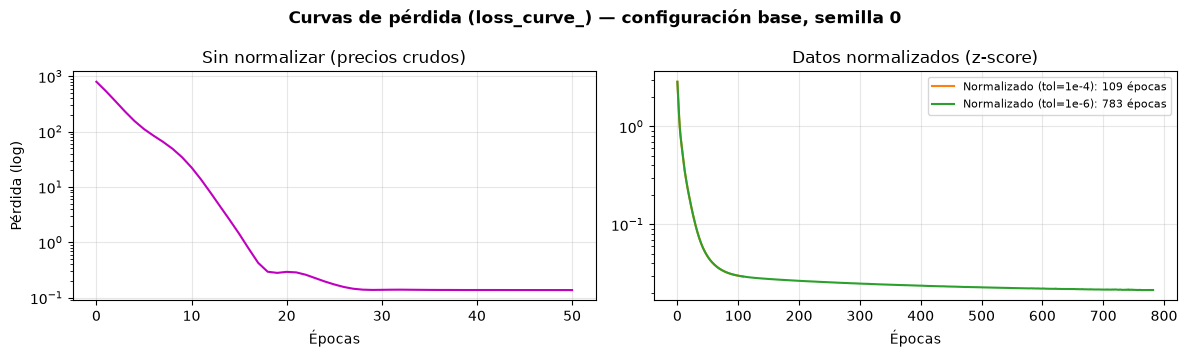

In [14]:
SEEDS = range(5)
variantes = {'Sin normalizar (tol=1e-4)':  dict(normalizar=False, tol=1e-4),
             'Normalizado (tol=1e-4)':     dict(normalizar=True,  tol=1e-4),
             'Normalizado (tol=1e-6)':     dict(normalizar=True,  tol=1e-6)}
ing_tr5, ing_te5 = ingenuo_mh(20, 5)

filas, curvas = [], {}
for nombre, kw in variantes.items():
    rs = [run_mh(20, 5, (10, 10, 10), 'identity', s, **kw) for s in SEEDS]
    curvas[nombre] = rs[0]['red'].loss_curve_                     # curva de pérdida (semilla 0)
    filas.append({'variante': nombre,
                  'épocas': np.mean([r['red'].n_iter_ for r in rs]),
                  'pérdida final': np.mean([r['red'].loss_ for r in rs]),
                  'RMSE_ent': np.mean([r['m_tr']['RMSE'].mean() for r in rs]),
                  'RMSE_prueba': np.mean([r['m_te']['RMSE'].mean() for r in rs]),
                  'RMSE_prueba_desv': np.std([r['m_te']['RMSE'].mean() for r in rs], ddof=1),
                  'pred t+1..t+5': ', '.join('%.3f' % v for v in np.mean([r['futuro'] for r in rs], 0))})
filas.append({'variante': 'Modelo ingenuo y(t+h)=y(t)', 'RMSE_ent': ing_tr5['RMSE'].mean(),
              'RMSE_prueba': ing_te5['RMSE'].mean(), 'pred t+1..t+5': ', '.join(['%.3f' % serie[-1]] * 5)})
exp1 = pd.DataFrame(filas).set_index('variante')
display(exp1.round(4))

# Curvas de pérdida: la pérdida sin normalizar está en (precio)^2 y la normalizada en unidades de sigma^2,
# por eso se grafican en escala logarítmica, cada una en su propio panel.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].semilogy(curvas['Sin normalizar (tol=1e-4)'], 'm-', lw=1.5)
ax[0].set(title='Sin normalizar (precios crudos)', xlabel='Épocas', ylabel='Pérdida (log)')
for nombre, c in [('Normalizado (tol=1e-4)', 'tab:orange'), ('Normalizado (tol=1e-6)', 'tab:green')]:
    ax[1].semilogy(curvas[nombre], color=c, lw=1.5, label='%s: %d épocas' % (nombre, len(curvas[nombre])))
ax[1].set(title='Datos normalizados (z-score)', xlabel='Épocas'); ax[1].legend(fontsize=8)
for a in ax: a.grid(alpha=.3)
fig.suptitle('Curvas de pérdida (loss_curve_) — configuración base, semilla 0', fontweight='bold')
fig.tight_layout(); plt.show()

#### Experimento 2: variación de entradas (rezagos), horizontes y arquitectura

**Rejilla:** 4 números de entradas (5, 10, 20, 30) × 4 horizontes (1, 3, 5 y 10 salidas) × 3 arquitecturas (`(10,)`, `(10,10,10)` del código base y `(50,25,10)`) × 2 activaciones (`identity` del código base y `tanh`) = **96 combinaciones**. Cada una se entrena con 5 semillas y se promedian los resultados. Todas usan datos normalizados, Adam y `tol=1e-6`.

**Métricas por combinación:** RMSE, MAPE y R² de prueba promediados sobre los horizontes. También se reportan el RMSE del horizonte más cercano ($t+1$) y el del más lejano ($t+H$).

**Criterio de comparación:** comparar el RMSE promedio entre combinaciones con distinto número de salidas no es justo, porque predecir 10 días es más difícil que predecir 1. Por eso se usa el **RMSE relativo**, $\text{RMSE}_{MLP}/\text{RMSE}_{ingenuo}$, calculado por horizonte y promediado: un valor menor que 1 significa que la red supera al modelo ingenuo.

In [15]:
n_ents   = [5, 10, 20, 30]
horiz    = [1, 3, 5, 10]
archs_mh = [(10,), (10, 10, 10), (50, 25, 10)]
acts     = ['identity', 'tanh']
ingenuos = {(ne, H): ingenuo_mh(ne, H) for ne in n_ents for H in horiz}

filas_mh, futuros = [], {}
for act in acts:
    for ne in n_ents:
        for H in horiz:
            ref_te = ingenuos[(ne, H)][1]['RMSE']              # RMSE del ingenuo por horizonte
            for a in archs_mh:
                rs = [run_mh(ne, H, a, act, s) for s in SEEDS]
                rm_te = np.mean([r['m_te']['RMSE'] for r in rs], 0)   # RMSE prueba por horizonte
                fut = np.mean([r['futuro'] for r in rs], 0)
                futuros[(act, ne, H, str(a))] = fut
                red = rs[0]['red']
                filas_mh.append(dict(
                    activacion=act, entradas=ne, salidas=H, arquitectura=str(a),
                    parametros=sum(c.size for c in red.coefs_) + sum(c.size for c in red.intercepts_),
                    epocas=np.mean([r['red'].n_iter_ for r in rs]),
                    RMSE_ent=np.mean([r['m_tr']['RMSE'].mean() for r in rs]),
                    RMSE_prueba=rm_te.mean(),
                    RMSE_t1=rm_te[0], RMSE_tH=rm_te[-1],
                    MAPE_prueba=np.mean([r['m_te']['MAPE'].mean() for r in rs]),
                    R2_prueba=np.mean([r['m_te']['R2'].mean() for r in rs]),
                    RMSE_rel=np.mean(rm_te / ref_te),
                    RMSE_prueba_desv=np.std([r['m_te']['RMSE'].mean() for r in rs], ddof=1),
                    pred_t1=fut[0], pred_tH=fut[-1]))
    print('Activación', act, 'terminada')

res_mh = pd.DataFrame(filas_mh)
print('Combinaciones probadas:', len(res_mh))

Activación identity terminada


Activación tanh terminada
Combinaciones probadas: 96


#### Tabla comparativa (todas las combinaciones)

Promedio de 5 semillas. `RMSE_t1` y `RMSE_tH` son el RMSE de prueba del primer horizonte y del último; `pred_t1` y `pred_tH` son los precios que la red predice para el día $T+1$ y para el día $T+H$ después del último dato. `RMSE_rel < 1` indica que la red supera al modelo ingenuo.

In [16]:
pd.set_option('display.max_rows', 200, 'display.width', 250, 'display.max_columns', 30)
res_mh.round(4)

,activacion,entradas,salidas,arquitectura,parametros,epocas,RMSE_ent,RMSE_prueba,RMSE_t1,RMSE_tH,MAPE_prueba,R2_prueba,RMSE_rel,RMSE_prueba_desv,pred_t1,pred_tH
0,identity,5,1,"(10,)",71,814.8,0.1080,0.0901,0.0901,0.0901,0.3210,0.7365,0.9785,0.0018,17.3688,17.3688
1,identity,5,1,"(10, 10, 10)",291,306.8,0.1078,0.0902,0.0902,0.0902,0.3198,0.7358,0.9798,0.0011,17.3667,17.3667
2,identity,5,1,"(50, 25, 10)",1846,141.6,0.1078,0.0914,0.0914,0.0914,0.3295,0.7285,0.9931,0.0019,17.3653,17.3653
3,identity,5,3,"(10,)",93,916.6,0.1374,0.1169,0.0894,0.1457,0.4542,0.5416,1.0265,0.0018,17.3722,17.3915
4,identity,5,3,"(10, 10, 10)",313,503.4,0.1371,0.1159,0.0920,0.1436,0.4423,0.5513,1.0207,0.0010,17.3690,17.3852
5,identity,5,3,"(50, 25, 10)",1868,155.4,0.1368,0.1159,0.0907,0.1437,0.4496,0.5508,1.0197,0.0009,17.3745,17.3887
6,identity,5,5,"(10,)",115,983.2,0.1586,0.1421,0.0904,0.1898,0.5600,0.3077,1.0177,0.0007,17.3733,17.4053
7,identity,5,5,"(10, 10, 10)",335,493.8,0.1587,0.1432,0.0918,0.1912,0.5700,0.2981,1.0263,0.0008,17.3725,17.4130
8,identity,5,5,"(50, 25, 10)",1890,174.8,0.1584,0.1419,0.0912,0.1898,0.5565,0.3104,1.0162,0.0006,17.3728,17.4075
9,identity,5,10,"(10,)",170,942.0,0.1990,0.1906,0.0932,0.2635,0.7885,-0.2363,1.0154,0.0005,17.3748,17.4550


#### Resumen: RMSE relativo por entradas y horizonte

Se promedian las 3 arquitecturas de cada activación. Después se muestra el RMSE de prueba promedio por arquitectura y el RMSE del modelo ingenuo para cada horizonte.

In [17]:
for act in acts:
    print(f'--- RMSE relativo (MLP / ingenuo), activación {act} ---')
    display(res_mh[res_mh.activacion == act].pivot_table(index='entradas', columns='salidas',
                                                         values='RMSE_rel', aggfunc='mean').round(3))
print('--- RMSE de prueba promedio por arquitectura ---')
display(res_mh.pivot_table(index='arquitectura', columns='activacion',
                           values=['RMSE_ent', 'RMSE_prueba', 'RMSE_rel'], aggfunc='mean')
              .loc[[str(a) for a in archs_mh]].round(4))
print('--- RMSE de prueba del modelo ingenuo por horizonte (10 salidas, 20 entradas) ---')
print(pd.Series(ingenuos[(20, 10)][1]['RMSE'], index=[f't+{h}' for h in range(1, 11)]).round(4).to_string())

--- RMSE relativo (MLP / ingenuo), activación identity ---


salidas,1,3,5,10
entradas,,,,
5,0.984,1.022,1.020,1.013
10,1.010,1.031,1.035,1.036
20,1.051,1.058,1.069,1.068
30,1.074,1.091,1.077,1.102


--- RMSE relativo (MLP / ingenuo), activación tanh ---


salidas,1,3,5,10
entradas,,,,
5,1.016,1.050,1.039,1.021
10,1.040,1.059,1.054,1.047
20,1.209,1.226,1.251,1.272
30,1.214,1.274,1.271,1.243


--- RMSE de prueba promedio por arquitectura ---


RMSE_ent         RMSE_prueba         RMSE_rel        
activacion   identity    tanh    identity    tanh identity    tanh
arquitectura                                                      
(10,)          0.1519  0.1519      0.1393  0.1461   1.0354  1.0944
(10, 10, 10)   0.1521  0.1493      0.1403  0.1545   1.0450  1.1614
(50, 25, 10)   0.1519  0.1452      0.1414  0.1553   1.0585  1.1727

--- RMSE de prueba del modelo ingenuo por horizonte (10 salidas, 20 entradas) ---
t+1     0.0945
t+2     0.1107
t+3     0.1426
t+4     0.1724
t+5     0.1907
t+6     0.2090
t+7     0.2200
t+8     0.2360
t+9     0.2500
t+10    0.2623


#### Selección de la configuración y predicción multihorizonte

La configuración se elige entre las de **5 salidas** (el horizonte de la práctica), tomando el menor RMSE relativo. Después se reportan las métricas de cada horizonte y el **precio predicho para cada uno de los 5 días siguientes**.

In [18]:
cand = res_mh[res_mh.salidas == 5].sort_values('RMSE_rel')
display(cand.head(6)[['activacion', 'entradas', 'arquitectura', 'parametros', 'RMSE_ent',
                      'RMSE_prueba', 'RMSE_rel', 'RMSE_prueba_desv', 'pred_t1', 'pred_tH']].round(4))

sel = cand.iloc[0]
cfg_sel = (int(sel.entradas), 5, ast.literal_eval(sel.arquitectura), sel.activacion)
rs_sel = [run_mh(*cfg_sel, s) for s in SEEDS]
ing_sel = ingenuos[(cfg_sel[0], 5)][1]
fut_sel = np.array([r['futuro'] for r in rs_sel])

tabla_sel = pd.DataFrame({
    'horizonte': [f'T+{h}' for h in range(1, 6)],
    'RMSE_prueba': np.mean([r['m_te']['RMSE'] for r in rs_sel], 0),
    'RMSE_ingenuo': ing_sel['RMSE'],
    'MAE_prueba': np.mean([r['m_te']['MAE'] for r in rs_sel], 0),
    'MAPE_prueba_%': np.mean([r['m_te']['MAPE'] for r in rs_sel], 0),
    'R2_prueba': np.mean([r['m_te']['R2'] for r in rs_sel], 0),
    'prediccion': fut_sel.mean(0),
    'prediccion_desv': fut_sel.std(0, ddof=1)}).set_index('horizonte')

print('Configuración seleccionada: %d entradas | 5 salidas | capas %s | %s | normalizado | Adam'
      % (cfg_sel[0], sel.arquitectura, sel.activacion))
print('Último dato real y(T) = %.2f\n' % serie[-1])
display(tabla_sel.round(4))
print('PREDICCIONES MULTIHORIZONTE (promedio de 5 semillas, desnormalizadas):')
for h, v in enumerate(fut_sel.mean(0), 1):
    print('   y(T+%d) = %.3f' % (h, v))

,activacion,entradas,arquitectura,parametros,RMSE_ent,RMSE_prueba,RMSE_rel,RMSE_prueba_desv,pred_t1,pred_tH
8,identity,5,"(50, 25, 10)",1890,0.1584,0.1419,1.0162,0.0006,17.3728,17.4075
6,identity,5,"(10,)",115,0.1586,0.1421,1.0177,0.0007,17.3733,17.4053
7,identity,5,"(10, 10, 10)",335,0.1587,0.1432,1.0263,0.0008,17.3725,17.4130
54,tanh,5,"(10,)",115,0.1584,0.1434,1.0299,0.0012,17.3449,17.3766
19,identity,10,"(10, 10, 10)",385,0.1593,0.1447,1.0303,0.0021,17.3708,17.4050
66,tanh,10,"(10,)",165,0.1588,0.1450,1.0338,0.0011,17.3420,17.3680


Configuración seleccionada: 5 entradas | 5 salidas | capas (50, 25, 10) | identity | normalizado | Adam
Último dato real y(T) = 17.36



,RMSE_prueba,RMSE_ingenuo,MAE_prueba,MAPE_prueba_%,R2_prueba,prediccion,prediccion_desv
horizonte,,,,,,,
T+1,0.0912,0.0924,0.0573,0.3278,0.7390,17.3728,0.0092
T+2,0.1124,0.1086,0.0786,0.4484,0.5987,17.3761,0.0135
T+3,0.1438,0.1397,0.0981,0.5596,0.3383,17.3860,0.0161
T+4,0.1722,0.1693,0.1204,0.6872,0.0460,17.3942,0.0115
T+5,0.1898,0.1874,0.1331,0.7596,-0.1699,17.4075,0.0092


PREDICCIONES MULTIHORIZONTE (promedio de 5 semillas, desnormalizadas):
   y(T+1) = 17.373
   y(T+2) = 17.376
   y(T+3) = 17.386
   y(T+4) = 17.394
   y(T+5) = 17.407


#### Gráficas de los casos representativos

Se grafican solo tres casos, usando la corrida cuya semilla queda más cerca del promedio:
1. **Mejor configuración (5 salidas):** se muestran los 5 horizontes en el conjunto de prueba, la trayectoria predicha y la curva de pérdida.
2. **Desempeño deficiente / subajuste:** la configuración base (20 entradas, `(10,10,10)`, `identity`) con el criterio de paro por defecto, que detiene a Adam antes de converger.
3. **Mayor complejidad, rezagos y horizonte:** 30 entradas, 10 salidas, `(50,25,10)` y `tanh`.

Para los casos 2 y 3 solo se muestran el primer horizonte, el último y la curva de pérdida, para no repetir gráficas.

In [19]:
def representativa(cfg, **kw):
    # Corre las 5 semillas y devuelve la de RMSE de prueba más cercano al promedio
    rs = [run_mh(*cfg, s, **kw) for s in SEEDS]
    rm = np.array([r['m_te']['RMSE'].mean() for r in rs])
    return rs[int(np.argmin(np.abs(rm - rm.mean())))]


def zoom(ax, o, h, color='r'):
    # Conjunto de prueba del horizonte h: real vs. predicción
    nd, t = o['nd'], np.arange(1, len(o['Y']) + 1)
    ax.plot(t[nd:], o['Y'][nd:, h - 1], 'b.-', lw=1, ms=3, label='Real')
    ax.plot(t[nd:], o['P'][nd:, h - 1], '.-', color=color, lw=1, ms=3, label='MLP')
    ax.set_title('Precio(t+%d) — RMSE=%.4f, R²=%.3f' % (h, o['m_te']['RMSE'][h - 1], o['m_te']['R2'][h - 1]), fontsize=10)
    ax.grid(alpha=.3); ax.legend(fontsize=7)


casos_mh = []
def registrar(nombre, o):
    casos_mh.append(dict(caso=nombre, epocas=o['red'].n_iter_, RMSE_ent=o['m_tr']['RMSE'].mean(),
                         RMSE_prueba=o['m_te']['RMSE'].mean(), RMSE_t1=o['m_te']['RMSE'][0],
                         RMSE_tH=o['m_te']['RMSE'][-1], R2_prueba=o['m_te']['R2'].mean(),
                         predicciones=', '.join('%.3f' % v for v in o['futuro'])))

##### Caso 1: mejor configuración

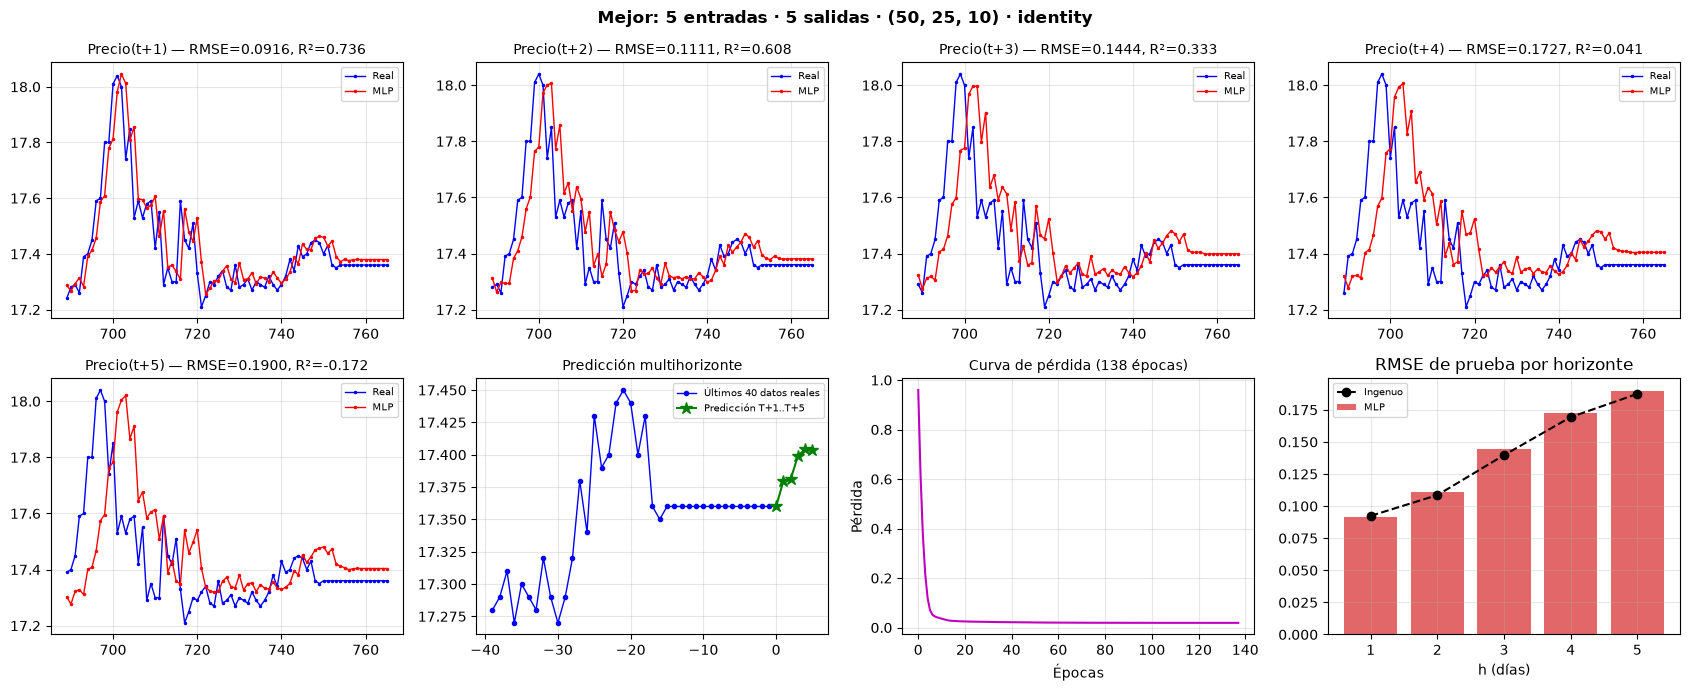

In [20]:
o1 = representativa(cfg_sel)
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
ax = ax.ravel()
for h in range(1, 6):
    zoom(ax[h - 1], o1, h)
# Trayectoria: últimos 40 días reales + 5 días predichos
ax[5].plot(np.arange(-39, 1), serie[-40:], 'b.-', lw=1, label='Últimos 40 datos reales')
ax[5].plot(np.arange(0, 6), np.r_[serie[-1], o1['futuro']], 'g*-', ms=9, label='Predicción T+1..T+5')
ax[5].set_title('Predicción multihorizonte', fontsize=10); ax[5].grid(alpha=.3); ax[5].legend(fontsize=7)
ax[6].plot(o1['red'].loss_curve_, 'm-', lw=1.5); ax[6].set_title('Curva de pérdida (%d épocas)' % o1['red'].n_iter_, fontsize=10)
ax[6].set(xlabel='Épocas', ylabel='Pérdida'); ax[6].grid(alpha=.3)
ax[7].bar(range(1, 6), o1['m_te']['RMSE'], color='tab:red', alpha=.7, label='MLP')
ax[7].plot(range(1, 6), ing_sel['RMSE'], 'ko--', label='Ingenuo')
ax[7].set(title='RMSE de prueba por horizonte', xlabel='h (días)'); ax[7].grid(alpha=.3); ax[7].legend(fontsize=7)
fig.suptitle('Mejor: %d entradas · 5 salidas · %s · %s' % (cfg_sel[0], sel.arquitectura, sel.activacion), fontweight='bold')
fig.tight_layout(); plt.show()
registrar('Mejor: %d ent · 5 sal · %s · %s' % (cfg_sel[0], sel.arquitectura, sel.activacion), o1)

##### Caso 2: desempeño deficiente / subajuste

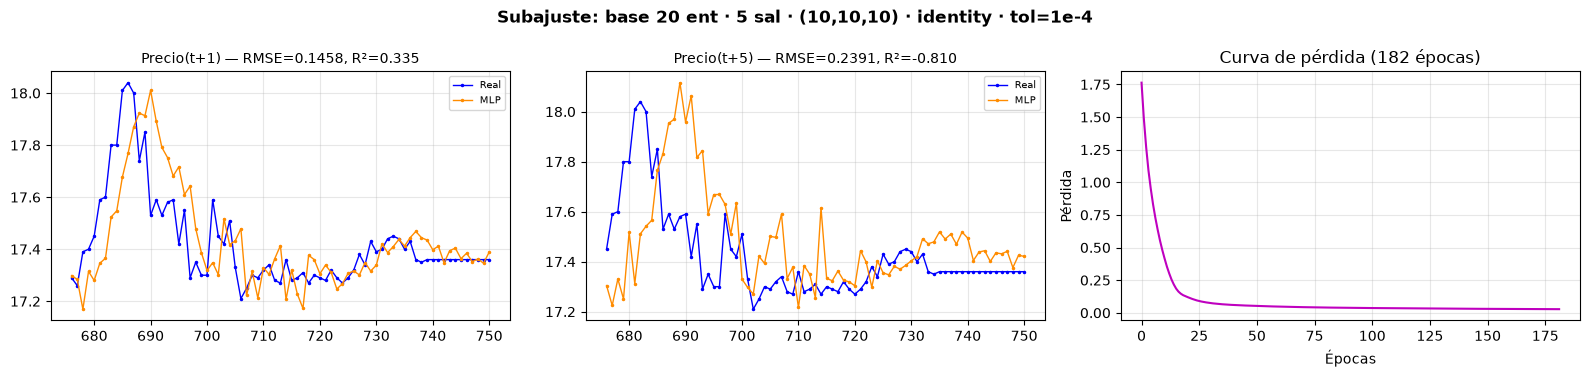

In [21]:
def figura_compacta(nombre, o, color):
    H = o['Y'].shape[1]
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    zoom(ax[0], o, 1, color); zoom(ax[1], o, H, color)
    ax[2].plot(o['red'].loss_curve_, 'm-', lw=1.5)
    ax[2].set(title='Curva de pérdida (%d épocas)' % o['red'].n_iter_, xlabel='Épocas', ylabel='Pérdida'); ax[2].grid(alpha=.3)
    fig.suptitle(nombre, fontweight='bold'); fig.tight_layout(); plt.show()
    registrar(nombre, o)

o2 = representativa((20, 5, (10, 10, 10), 'identity'), tol=1e-4)
figura_compacta('Subajuste: base 20 ent · 5 sal · (10,10,10) · identity · tol=1e-4', o2, 'darkorange')

##### Caso 3: mayor complejidad, rezagos y horizonte

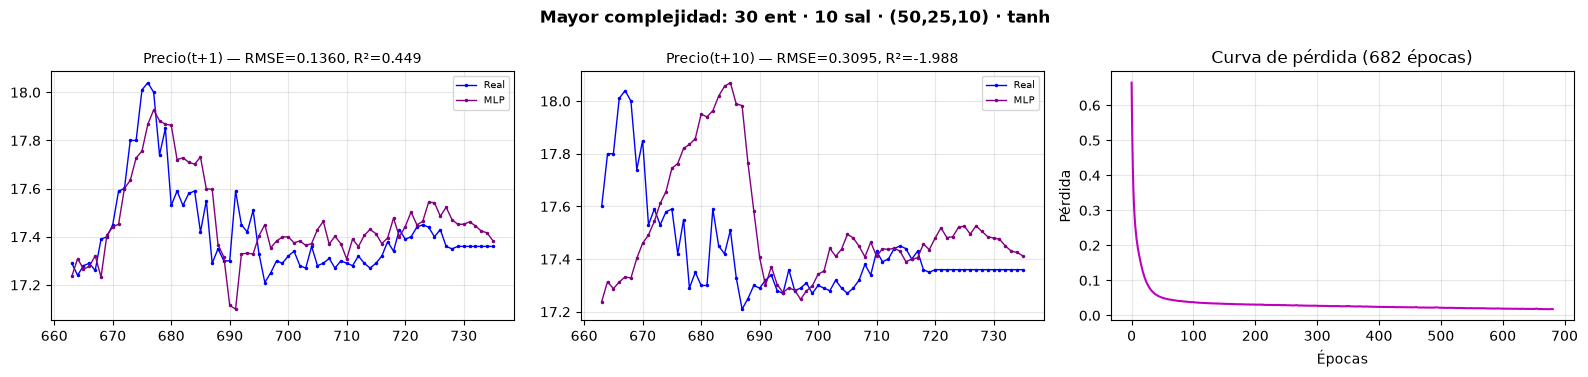

,epocas,RMSE_ent,RMSE_prueba,RMSE_t1,RMSE_tH,R2_prueba,predicciones
caso,,,,,,,
"Mejor: 5 ent · 5 sal · (50, 25, 10) · identity",138,0.1581,0.1420,0.0916,0.1900,0.3091,"17.380, 17.381, 17.399, 17.404, 17.404"
"Subajuste: base 20 ent · 5 sal · (10,10,10) · identity · tol=1e-4",182,0.1847,0.1869,0.1458,0.2391,-0.1388,"17.361, 17.383, 17.387, 17.411, 17.408"
"Mayor complejidad: 30 ent · 10 sal · (50,25,10) · tanh",682,0.1425,0.2395,0.1360,0.3095,-0.8616,"17.431, 17.415, 17.436, 17.436, 17.429, 17.439..."


RMSE ingenuo (20 ent, 5 sal): promedio 0.1408 | t+1 0.0933 | t+5 0.1886
RMSE ingenuo (30 ent, 10 sal): promedio 0.1899 | t+1 0.0958 | t+10 0.2600


In [22]:
o3 = representativa((30, 10, (50, 25, 10), 'tanh'))
figura_compacta('Mayor complejidad: 30 ent · 10 sal · (50,25,10) · tanh', o3, 'purple')

display(pd.DataFrame(casos_mh).set_index('caso').round(4))
print('RMSE ingenuo (20 ent, 5 sal): promedio %.4f | t+1 %.4f | t+5 %.4f'
      % (ing_te5['RMSE'].mean(), ing_te5['RMSE'][0], ing_te5['RMSE'][-1]))
ing30 = ingenuos[(30, 10)][1]['RMSE']
print('RMSE ingenuo (30 ent, 10 sal): promedio %.4f | t+1 %.4f | t+10 %.4f' % (ing30.mean(), ing30[0], ing30[-1]))

#### Datos de apoyo para el análisis

In [23]:
print('RMSE de entrenamiento y prueba promedio por número de entradas (todas las salidas y arquitecturas)')
display(res_mh.pivot_table(index='entradas', columns='activacion', values=['RMSE_ent', 'RMSE_prueba', 'RMSE_rel'],
                           aggfunc='mean').round(4))
print('RMSE relativo promedio por número de salidas')
display(res_mh.pivot_table(index='salidas', columns='activacion', values='RMSE_rel', aggfunc='mean').round(3))
print('Combinaciones con RMSE_rel < 1 (superan al ingenuo): %d de %d' % ((res_mh.RMSE_rel < 1).sum(), len(res_mh)))
print('Rango RMSE_rel  identity: %.3f – %.3f | tanh: %.3f – %.3f' % (
      res_mh[res_mh.activacion == 'identity'].RMSE_rel.min(), res_mh[res_mh.activacion == 'identity'].RMSE_rel.max(),
      res_mh[res_mh.activacion == 'tanh'].RMSE_rel.min(), res_mh[res_mh.activacion == 'tanh'].RMSE_rel.max()))
print('Rango de predicciones pred_t1 entre todas las combinaciones: %.3f – %.3f' % (res_mh.pred_t1.min(), res_mh.pred_t1.max()))

RMSE de entrenamiento y prueba promedio por número de entradas (todas las salidas y arquitecturas)


RMSE_ent         RMSE_prueba         RMSE_rel        
activacion identity    tanh    identity    tanh identity    tanh
entradas                                                        
5            0.1507  0.1498      0.1348  0.1368   1.0098  1.0313
10           0.1511  0.1490      0.1378  0.1399   1.0280  1.0502
20           0.1526  0.1495      0.1426  0.1654   1.0615  1.2393
30           0.1536  0.1469      0.1461  0.1659   1.0859  1.2506

RMSE relativo promedio por número de salidas


activacion,identity,tanh
salidas,,
1,1.030,1.120
3,1.051,1.152
5,1.050,1.154
10,1.055,1.146


Combinaciones con RMSE_rel < 1 (superan al ingenuo): 5 de 96
Rango RMSE_rel  identity: 0.978 – 1.166 | tanh: 1.006 – 1.352
Rango de predicciones pred_t1 entre todas las combinaciones: 17.293 – 17.411


<a id="p2-analisis"></a>

### 3.5 Análisis y conclusiones de la práctica

**La normalización es indispensable con Adam.** En el Experimento 1, la red sin normalizar empieza con una pérdida de ~800 (en unidades de precio al cuadrado), porque tiene que aprender a producir valores cercanos a 17 desde pesos que empiezan cerca de 0. Se detiene a las ~50 épocas con un RMSE de prueba de 0.279, el doble que el modelo ingenuo, y con mucha variación entre semillas (desviación de 0.071): cada inicialización termina en un lugar distinto. Con z-score, la pérdida empieza cerca de 1 y baja de forma suave y reproducible (desviación de 0.002 a 0.009).

**Caso deficiente: el criterio de paro también importa.** Aunque los datos estén normalizados, con `tol = 1e-4` Adam se detiene a las ~120 épocas. Su error de entrenamiento (0.184) es **mayor que el del modelo ingenuo** (0.162), que es la señal típica de **subajuste**: la red no alcanzó ni siquiera la solución trivial de copiar el último precio. En la curva de pérdida (las líneas naranja y verde coinciden hasta que la naranja se corta) se ve que la pérdida todavía bajaba cuando el entrenamiento se detuvo. Al usar `tol = 1e-6`, la red entrena ~590 épocas y el RMSE de prueba baja de 0.186 a 0.150. En la gráfica del Caso 2, la predicción de $t+1$ va visiblemente desfasada de la serie real (RMSE = 0.146 contra 0.093 del ingenuo).

**El error crece con el horizonte, para la red y para el ingenuo.** Con 10 salidas, el RMSE del modelo ingenuo pasa de 0.095 en $t+1$ a 0.262 en $t+10$, y el MLP sigue casi la misma curva. En la configuración seleccionada, el R² de prueba cae de 0.74 en $T+1$ a 0.05 en $T+4$ y es negativo en $T+5$: a partir del cuarto día, la red predice peor que la media del periodo de prueba. Esto tiene sentido en una serie que se comporta como paseo aleatorio, porque la incertidumbre se acumula con cada día. Por eso se usa el RMSE relativo, que fue casi constante entre horizontes (identity: 1.03, 1.05, 1.05 y 1.06 para 1, 3, 5 y 10 salidas). Que la red tenga que predecir varios horizontes a la vez con capas compartidas no la perjudica más allá de la dificultad natural de cada horizonte.

**Efecto del número de entradas.** Menos entradas es mejor. Con `identity`, el RMSE relativo promedio sube de 1.010 (5 entradas) a 1.086 (30 entradas). Con `tanh` sube de 1.031 a 1.251, y su error de entrenamiento baja (0.150 → 0.147) mientras el de prueba sube (0.137 → 0.166): con más entradas, la red no lineal empieza a memorizar ruido, igual que en la Práctica 1.

**Efecto de la arquitectura y de la activación.** Con `identity`, la arquitectura casi no influye (RMSE relativo de 1.035, 1.045 y 1.059 para `(10,)`, `(10,10,10)` y `(50,25,10)`), porque la red es lineal sin importar cuántas capas tenga. Con `tanh`, las redes grandes empeoran (1.094 → 1.173). En las 16 combinaciones de entradas y horizontes (promediando arquitecturas) `identity` superó a `tanh` (RMSE relativo de 1.03-1.06 contra 1.12-1.15 por horizonte), lo que confirma que en esta serie no hay relaciones no lineales que una red más flexible pueda aprovechar.

**Caso de mayor complejidad.** Con 30 entradas, 10 salidas, `(50,25,10)` y `tanh` (3,195 parámetros), el error de entrenamiento (0.143) queda **por debajo** del ingenuo en entrenamiento (0.205), pero el de prueba (0.240) queda **por encima** del ingenuo en prueba (0.190). Es un sobreajuste claro. En la gráfica de $t+10$ la red reproduce el pico del día ~680 con un desfase de casi 10 días, y su trayectoria futura se aleja del último precio (17.43-17.44).

**Comparación con el modelo ingenuo.** Solo **5 de las 96 combinaciones** tienen RMSE relativo menor que 1, y las 5 son de **una sola salida** con activación `identity` (la mejor: 5 entradas y `(10,)`, RMSE = 0.0901, 2.2 % mejor que el ingenuo). Esto coincide con la Práctica 1. Con 3 o más salidas, ninguna red supera al modelo ingenuo, aunque las mejores quedan a menos del 2 % de él.

**Configuración elegida y predicciones.** Entre las configuraciones de 5 salidas, la de menor RMSE relativo es **5 entradas, `(50,25,10)`, `identity`, datos normalizados y Adam** (RMSE relativo = 1.016, RMSE de prueba promedio = 0.142). Como la activación es lineal, esta red equivale a un modelo autorregresivo con 5 rezagos. La diferencia con `(10,)` (1.018) es menor que la variación entre semillas, así que la red de 115 parámetros sería igual de válida y más sencilla. Los valores predichos para cada horizonte (promedio de 5 semillas, desnormalizados) son:

| Horizonte | $T+1$ | $T+2$ | $T+3$ | $T+4$ | $T+5$ |
|---|---|---|---|---|---|
| Predicción | **17.373** | **17.376** | **17.386** | **17.394** | **17.407** |
| RMSE de prueba (MLP) | 0.091 | 0.112 | 0.144 | 0.172 | 0.190 |
| RMSE de prueba (ingenuo) | 0.092 | 0.109 | 0.140 | 0.169 | 0.187 |

La red predice un aumento muy ligero, de ~0.05 en cinco días, a partir del último dato (17.36). Este movimiento es mucho menor que el RMSE de cada horizonte, así que en la práctica la predicción dice que el precio se mantendrá alrededor de 17.36-17.41. En resumen, el MLP multihorizonte reproduce bien la forma de la serie y la normalización hace que su entrenamiento sea estable y reproducible, pero no aporta información sobre los próximos días que no estuviera ya en el último precio conocido.

<a id="conclusiones"></a>

## 4. Conclusiones

<a id="conclusiones-personales"></a>

### 4.1 Conclusiones personales

**Dayanni**

Me tocó preparar la estructura del reporte y el marco teórico de las dos prácticas, y eso me obligó a entender bien qué hace el código antes de ver los resultados. Lo que más me ayudó fue ver cómo una serie de tiempo, que en principio no tiene "entradas" y "salidas", se vuelve un problema supervisado con la matriz de rezagos: cada fila es un pedazo del pasado y la respuesta correcta es el precio que sigue. También aprendí a revisar con cuidado el orden de las columnas: en la Práctica 2 la primera salida es el horizonte más lejano y no el más cercano, y en la Práctica 1 la entrada que usaba el código base para la predicción futura en realidad estimaba el último dato que ya conocíamos. Otra cosa que me quedó clara es que, con la activación `identity`, la red sigue siendo lineal aunque tenga varias capas, así que agregar capas no le da más capacidad; para eso se necesita una activación no lineal y, en ese caso, normalizar los datos para que no se sature y para que Adam avance con pasos adecuados. Finalmente, ver en la Práctica 1 que la mejor red apenas mejoró al modelo ingenuo me hizo entender que un MLP no adivina el futuro: describe bien el comportamiento reciente del precio, pero siempre hay que compararlo con un modelo sencillo antes de confiar en sus predicciones.

**Valeria Esmer**

Con esta práctica aprendí que una red más compleja no necesariamente ofrece mejores resultados. Después de probar 96 combinaciones, las redes más sencillas tuvieron mejor desempeño y el modelo ingenuo obtuvo resultados muy similares. También comprendí la importancia de revisar el código y validar las predicciones con datos que no se utilizaron en el entrenamiento. Finalmente, considero que el MLP puede ser útil para estimar precios, pero sus resultados deben tomarse como una referencia y no como una señal directa de inversión.

**Fernanda**

Me tocó programar y probar la Práctica 2. Lo que más me sorprendió fue lo mucho que importan detalles que no son la arquitectura. Sin normalizar, Adam empezaba con una pérdida enorme y cada semilla terminaba en un resultado distinto; con z-score todo se volvió estable. Aun normalizando, el criterio de paro por defecto cortaba el entrenamiento antes de tiempo y la red quedaba peor que copiar el último precio. Si no hubiera comparado contra el modelo ingenuo, habría pensado que el problema era la red y no el entrenamiento. También aprendí que, para comparar predicciones con distinto número de días hacia adelante, no basta con ver el RMSE, porque predecir 10 días siempre va a tener más error que predecir uno; por eso usé el error relativo al modelo ingenuo. Al final, la mejor red quedó casi igual que el modelo ingenuo y el error creció con cada día de horizonte. Me quedo con que un modelo más grande no arregla que la serie casi no tenga patrones, y que lo valioso del ejercicio es saber medir y explicar por qué pasa eso.

**Estephany**

Mi parte fue revisar e integrar el reporte, y eso me hizo ver lo fácil que es que el texto y los resultados dejen de coincidir. Al volver a ejecutar todo el notebook, la mejor configuración de la Práctica 1 cambió ligeramente y varias cifras del análisis tuvieron que actualizarse. Además, una de las gráficas representativas no se generaba porque la celda estaba guardada como texto. Aprendí que un reporte técnico tiene que poder ejecutarse de principio a fin y que cada número del análisis debe salir de una tabla, no de memoria. Revisar las dos prácticas juntas también me ayudó a ver que llegan a la misma conclusión por caminos distintos: el MLP sigue muy bien la forma de la serie, pero casi no supera al modelo ingenuo, y lo más importante para obtener resultados confiables fue preparar bien los datos y el entrenamiento.

<a id="conclusiones-generales"></a>

### 4.2 Conclusiones generales

En las dos prácticas se usó un perceptrón multicapa de regresión para predecir el precio de un activo de la BMV a partir de sus valores pasados. En total se probaron **192 combinaciones**: 96 en cada práctica, cada una con 5 semillas.

| Aspecto | Práctica 1 (un paso) | Práctica 2 (multihorizonte) |
|---|---|---|
| Salidas | 1 (día siguiente) | 1, 3, 5 o 10 días a la vez |
| Datos y entrenamiento | Sin escalar (A) y estandarizados (B), L-BFGS | Normalizados (z-score), Adam |
| Mejor configuración | 3 rezagos, `(50,25,10)`, `tanh` | 5 entradas, `(50,25,10)`, `identity` (5 salidas) |
| RMSE de prueba vs. ingenuo | 0.0889 vs. 0.0920 (3.4 % mejor) | 0.142 vs. 0.140 (1.6 % peor, promedio de 5 horizontes) |
| Predicción reportada | $\hat{y}(T+1) = 17.384$ | 17.373, 17.376, 17.386, 17.394, 17.407 |

**Coincidencias.**
1. **La serie se parece a un paseo aleatorio.** En ambas prácticas el modelo ingenuo $\hat{y}(t+h) = y(t)$ es muy difícil de superar. Las únicas redes que lo mejoran son las de un paso, y solo por 2-3 %, una diferencia del mismo orden que la variación entre semillas.
2. **Más complejidad no significa mejores resultados.** Con activación lineal, agregar capas no cambia nada, porque la red sigue siendo una regresión lineal sobre los rezagos. Con `tanh`, más capas o más rezagos hacen que el error de entrenamiento baje y el de prueba suba: es sobreajuste.
3. **Pocos rezagos son suficientes.** Las mejores configuraciones usan 3 o 5 valores pasados; con 20 o 30, el desempeño en prueba empeora en las dos prácticas.

**Diferencias.**
1. **El error crece con el horizonte.** En la Práctica 1 el error de prueba ronda 0.09. En la Práctica 2, el RMSE pasa de 0.09 en $T+1$ a 0.19 en $T+5$ y a 0.26 en $T+10$, y el R² se vuelve negativo desde el cuarto o quinto día. La predicción del día siguiente es la única con un margen de error pequeño respecto a la variación del precio.
2. **El entrenamiento importa tanto como la arquitectura.** L-BFGS converge bien con datos crudos, pero Adam necesita datos normalizados y un criterio de paro adecuado. Sin eso, la red queda en subajuste y es peor que el modelo ingenuo, aunque la arquitectura sea la misma.
3. **La no linealidad ayuda solo en la Práctica 1.** Allí, `tanh` con 3 rezagos fue ligeramente mejor que la red lineal. En la Práctica 2, `identity` superó a `tanh` en todas las combinaciones de entradas y horizontes, porque predecir más días con más parámetros amplifica el sobreajuste.

**Conclusión final.** El MLP reproduce bien el comportamiento de la serie y sus predicciones para los próximos días (17.37-17.41) son coherentes con el último precio conocido (17.36). Sin embargo, con solo los precios pasados de un activo no logra anticipar movimientos que el modelo ingenuo no capture. Para un uso real habría que agregar información adicional (otros activos, volumen, indicadores económicos), validar con varios periodos de prueba y tomar las predicciones como referencia y no como señal de inversión. Lo más valioso de las dos prácticas fue aprender a convertir una serie de tiempo en un problema supervisado, a separar los datos sin usar el futuro y a comparar siempre contra un modelo de referencia sencillo.